# Lecture 16: Solving an exam

# Documentation reminder
- [Numpy User Guide](https://docs.scipy.org/doc/numpy/numpy-user-1.17.0.pdf)
- [Numpy Reference Documentation](https://docs.scipy.org/doc/numpy/numpy-ref-1.17.0.pdf)
- [Scipy Reference Guide](https://docs.scipy.org/doc/scipy/scipy-ref-1.4.1.pdf)
- [Matplotlib Documentation](https://matplotlib.org/3.1.3/Matplotlib.pdf)

# Question 1: Strings and files (6p)

### Part A (1p)

Colors can be defined using Red, Green, and Blue color combinations (RGB colors). Given the RGB values the luminance $L$ of a color can be computed as:

$$ L = 0.2126 \cdot R + 0.7152 \cdot G + 0.0722 \cdot B $$

Write a function to converts integer red green and blue color values to integer greyscale.

**Example usage**
```python
>>> print(luminance(red=40, green=200, blue=130))
161
```

In [ ]:
# Write solution here

##### Solution proposal:

In [3]:
def luminance(red, green, blue):
    return round(0.2126 * red + 0.7152 * green + 0.0722 * blue)

### Part B (5p)

**Task:** Write an image file converter that converts files from the RGB color image format `ppm` to the grayscale format `pgm` using the `luminance` function from part A. 

Use your converter to transform the given file `kitten.ppm` to the PGM formatted file `kitten.pgm`.

In [12]:
# Just convert the ppm file to something we can look at in the notebook (png format)
!convert kitten.ppm kitten_ppm.png

![Kitten](kitten_ppm.png)

### Background

#### The PPM image file format

The PPM image format (file.ppm) is a simple text based image format 
```bash
P3
# The P3 means colors are in ASCII, then 3 columns and 2 rows,
# then 255 for max color, then RGB triplets
3 2
255
103 217 103    43  95 181   219 219 219
244  83 106   255 255 255     0  83 106
```
The lines starting with `#` are comments and can be ignored.

The first characters `P3` denote the file format, the second two numbers are the width and height in pixels. The next number denotes the maximum value of the channels here 255. The other numbers are RGB color values, pixel by pixel. The first pixel has R=103, G=217, B=103, etc. 

Note that linebreaks are optional and that any whitespace seperator works, e.g. this is also a valid PPM file:
```bash
P3
3 2
255
103 217 103 43 95 181 219 219 219 244 83 106 255 255
255 0 83 106
```

#### The PGM format

The PGM image format looks very similar, but has only 1 channel per pixel (the luminance / greyscale)
```bash
P2
# Greyscale version
3 2
255
185 90 219
119 255 67
```

In [ ]:
# Write a ppm file reader here

In [ ]:
# Write a RGB to Luminance converter here

In [ ]:
# Write a pgm file writer here

##### Solution proposal:

In [114]:
def read_ppm(filename):
    
    with open(filename, 'r') as file:
        assert 'P3' in file.readline()        
        data = []
        for line in file:
            if not line.startswith("#"):
                data += [ int(word) for word in line.strip().split() ]

    (width, height, color_max), data = data[:3], data[3:]
    
    return data, width, height, color_max

In [115]:
def write_pgm(filename, data, width, height, color_max):
 
    header = f"""P2
# Greyscale version
{width} {height}
{color_max}
"""
    body = '\n'.join([str(x) for x in data]) + '\n'
    
    with open(filename, 'w') as file:
        file.write(header)
        file.write(body)

In [119]:
def ppm2pgm(filename):

    data, width, height, color_max = read_ppm(filename)

    R, G, B = data[0::3], data[1::3], data[2::3]
    grays = [ luminance(r, g, b) for r, g, b in zip(R, G, B)]

    out_filename = filename.replace('ppm', 'pgm')
    write_pgm(out_filename, grays, width, height, color_max)

In [95]:
filename = 'kitten.ppm'
ppm2pgm(filename)

In [96]:
!ls kitten.pgm
!convert kitten.pgm kitten_pgm.png

kitten.pgm


![](kitten_pgm.png)

# Question 2: Numpy  (5p)

The speed $v(t)$ as a function of time $t$ of a body (initially at rest) moving along a sloping plane in a viscous liquid can be written as:

$$ v(t) = \frac{m  g}{\eta}  \sin(\theta) \times \left(1 - \exp(- \frac{\eta}{m} t) \right) $$

were $m$ is the mass of the body, $m = 1\,$kg, $g$ is the gravitational acceleration, $g = 9.81$ m/s$^2$, $\theta$ the sloping angle of the plane relative to the horizontal plane, $\theta = 60^\circ$ and $\eta$ is the viscosity of the liquid, $\eta = 0.05\,$kg/s. This problem has to be solved using NumPy, SciPy, and MatPlotLib.

### Part A

At what time has the body reached the speed $v_1 = 100\,$m/s?<br>
Hint: Use a suitable function from SciPy to solve the equation $v(t) - v_1 = 0$.

### Part B

Use MatPlotLib to plot $v(t)$ as a function of $t$ together with the solution found in Part A

### Part C

Use the result from Part B to estimate the terminal velocity of the body, i.e. $v_{term} \equiv \lim_{t\rightarrow \infty} v(t)$.

In [ ]:
# Solve Part A here

In [ ]:
# Solve Part B here

##### Solution proposal:

In [110]:
import numpy as np

m, g, theta, eta = 1., 9.81, 2/3 * np.pi, 0.05

def velocity(t):
    return m * g * np.sin(theta) / eta * (1 - np.exp(- eta / m * t))

from scipy.optimize import root

v1 = 100.
root_function = lambda t: velocity(t) - v1
sol = root(root_function, x0=0.0)
ts = sol.x[0]

print(f'The velocity v is {v1} at time ts = {ts} (check: {velocity(ts)})')

The velocity v is 100.0 at time ts = 17.760499212265156 (check: 99.99999999999946)


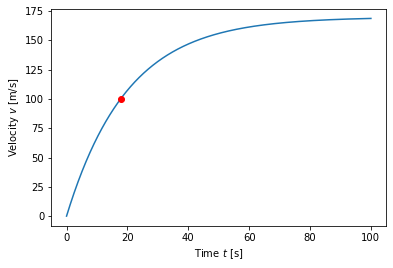

Terminal velocity: 169.9141842225069


In [109]:
t = np.linspace(0., 100., num=1000)
v = velocity(t)

import matplotlib.pyplot as plt
plt.plot(t, v)
plt.plot(ts, v1, 'ro')
plt.xlabel('Time $t$ [s]')
plt.ylabel('Velocity $v$ [m/s]')
plt.show()

vt = velocity(ts * 1000)
print('Terminal velocity:', vt)

# Question 3. Designing a class (6p)

A common type of matrices has the block matrix form:

$$ A = \begin{pmatrix} K & G \\ G^T & 0 \end{pmatrix} $$

where $K$ and $G$ in turn are matrices, and $K$ represents a system of equations, and $G$ represents a set of constraints.

## Part A (4p)

Write a class `ConstrainedMatrix` whoose constructor takes the two matrices $K$ and $G$ and represents the $A$ matrix described above. Make sure to only store a single copy of $K$ and $G$ in the class.

Implement the methods

 * `shape()` that returns the rows and columns of $A$ as a tuple
 * `dot(x)` that returns the matrix-vector product $A \cdot x$ as an `ndarray`
 
The matrices `K` and `G` and the vector `x` must also be NumPy `ndarray`s.

#### Hints

- The matrix-vector product is defined as:
$
\begin{aligned}
M \cdot x \equiv \sum_j M_{ij} x_j \, , \quad
M^T \cdot x \equiv \sum_j x_j M_{ji}
\end{aligned}
$
- In the `dot` method use that
$
\begin{aligned}
A \cdot x = \begin{pmatrix} K & G \\ G^T & 0 \end{pmatrix} \cdot \begin{pmatrix} x_k \\ x_g \end{pmatrix} = \begin{pmatrix} K \cdot x_k + G \cdot x_g \\ G^T \cdot x_k \end{pmatrix}
\end{aligned}
$
- The shape of a NumPy `ndarray` is given by the `.shape` property.

In [ ]:
# Implement ConstrainedMatrix here

In [136]:
# Provided test example

K = np.array([
    [1,2,3],
    [4,5,6],
    [7,8,9]])

G = np.array([
    [1, 0],
    [0,-1],
    [-1,1]])

x = np.array([1,0,2,3,0])

A = ConstrainedMatrix(K, G)
print(A.shape()) # should be (5, 5)

y = A.dot(x)
print(y) # should be [10, 16, 22, -1, 2]

(5, 5)
[10 16 22 -1  2]


##### Solution proposal:

In [128]:
class ConstrainedMatrix:
    def __init__(self, K, G):
        self.K, self.G = K, G

    def shape(self):
        rows = k.shape[0] + g.shape[1]
        cols = k.shape[1] + g.shape[1]
        return rows, cols

    def dot(self, x):
        """ Computes the matrix-vector product A * x = y """

        pos = self.K.shape[1]
        x_k, x_g = x[:pos], x[pos:]
        
        y_k = np.dot(self.K, x_k) + np.dot(self.G, x_g)
        y_g = np.dot(x_k, self.G)
        
        return np.concatenate((y_k, y_g))

In [133]:
# Provided test example

K = np.array([
    [1,2,3],
    [4,5,6],
    [7,8,9]])

G = np.array([
    [1, 0],
    [0,-1],
    [-1,1]])

x = np.array([1,0,2,3,0])

A = ConstrainedMatrix(K, G)
y = A.dot(x)

print(y) # should be [10, 16, 22, -1, 2]

[10 16 22 -1  2]


Part B (2p)
-----------

You want to add a check that the number of rows and columns in `K` are equal to the number of rows in `G`. 
When this is not the case you want your class to throw an exception. 

Create the custom exception `MatrixSizeMismatch` together with a new class `SafeConstrainedMatrix` that throws the custom exception together with an informative error message if `K` and `G` does not have the same number of rows.

**Also** write a simple test code that catches the exception.

In [ ]:
# Implement the exception and the new class here

##### Solution proposal:

In [137]:
class MatrixSizeMismatch(Exception):
    pass

class SafeConstrainedMatrix(ConstrainedMatrix):
    def __init__(self, K, G):
        
        K_rows, K_cols = K.shape
        G_rows = G.shape[0]
        
        if K_rows != G_rows or K_cols != G_rows:
            raise MatrixSizeMismatch(
                f"Incompatible matrices: K.shape = {K.shape} while G has {G_rows} rows")
        
        super().__init__(K, G)

In [144]:
G = np.array([
    [1, 0],
    [0,-1],
    [-1,1]])

K = np.array([
    [1,2],
    [3,4],
    [5,6]])

try:
    A = SafeConstrainedMatrix(K, G)
except MatrixSizeMismatch as e:
    print(e)

Incompatible matrices: K.shape = (3, 2) while G has 3 rows


# Question 4. Designing a class hierarchy (8p)

Vectors are a critical part of almost any software.

Object Oriented Programming can be used to make special versions of vectors for practical and performance reasons. 

Please do not use NumPy or SciPy for this question. Instead use the `sqrt` funtion from the `math` module.

Part A (0.5p)
-------------

Write a base class `BaseVector` with the abstract methods
- `norm(self)` that should return the vector norm
- `__len__(self)` that should return the length of the vector
- `_getitem(self, index)` that should return the element with index `index`

and the real methods
- `__getitem__(self, index)` that returns `self._getitem(index)` if the index is within the bounds and if not, raises `IndexError`.
- `__str__` that uses the `len` and indexing (getitem) to create a string representation of the vector.

**Hints:**
- The `norm` is defined as $\sqrt{\sum_i a_i^2}$
- The `__len__(self)` method enables  `len(v)` function
- The `__getitem__(self, item)` method enables square bracked indexing `v[index]`

In [231]:
import abc

class BaseVector(metaclass=abc.ABCMeta):

    @abc.abstractmethod
    def norm(self): pass

    @abc.abstractmethod
    def __len__(self): pass

    @abc.abstractmethod
    def _getitem(self, index): pass
    
    def __getitem__(self, index):
        if index < 0 or index > len(self):
            raise IndexError(f'Index {index} outside range for lenght {len(self)}')
        return self._getitem(index)
        
    def __str__(self):
        return '[' + ', '.join([ str(self[index]) for index in range(len(self)) ]) + ']'
    
    # Part E
    def slice(self, start, end):
        if start < 0 or end < 0 or start > len(self) or end > len(self):
            raise IndexError(f'Slice {start}:{end} outside length {len(self)}')
        return self._slice(start, end)

    @abc.abstractmethod
    def _slice(self, start, end): pass    

Part B (1p)
-----------

Write a subclass `ZeroVector` (a vector of all zeros) whoose constructor that only takes a length.

Add implementations to the `len` operator the `norm` and `x[i]` (getitem) methods.

In [232]:
class ZeroVector(BaseVector):

    def __init__(self, length):
        self.length = length

    def __len__(self): return self.length
    def _getitem(self, index): return 0
    def norm(self): return 0

    def _slice(self, start, end): return ZeroVector(end - start)

In [233]:
# Given example code

x = ZeroVector(10)
print(x)
print(x.norm())
print(x[5])

try:
    print(x[15])
except IndexError as e:
    print(e)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
0
0
Index 15 outside range for lenght 10


Part C (2p)
-----------

Write a subclass `Vector` that is a ordinary vector whoose constructor takes a `list` of values and stores it internally.

Add implementations to the `len` operator the `norm` and `x[i]` (getitem) methods.

In [241]:
from math import sqrt

class Vector(BaseVector):

    def __init__(self, values):
        self.values = values

    def __len__(self): return len(self.values)
    def _getitem(self, index): return self.values[index]
    def norm(self): return sqrt(sum( (x**2 for x in self.values) ))

    def _slice(self, start, end): return VectorSlice(self, start, end)

In [242]:
# Given example code

x = Vector([3, 2, 6, 4, 2, 8])
print(x.norm(), 'ref 11.533')

11.532562594670797 ref 11.533


Part D (3p)
-----------

Write a subclass `VectorSlice` that takes a `Vector` and a range in terms of a `start` and `end` index and represents the vector slice without copying any data.

Do this by storing a reference to the original vector, and uses the `start` and `end` range to determine what part of the vector to use.

Add implementations to the `len` operator, the `norm` and `x[i]` (getitem) methods.

In [243]:
class VectorSlice(BaseVector):
    
    def __init__(self, vector, start, end):
        self.vector = vector
        self.start, self.end = start, end

    def __len__(self): return self.end - self.start
    def _getitem(self, index): return self.vector[self.start + index]
    def norm(self): return sqrt(sum(( self.vector[idx]**2 for idx in range(self.start, self.end) )))

    def _slice(self, start, end):
        return VectorSlice(self.vector, self.start + start, self.start + end)

In [244]:
x = Vector([1, 3, 5, 7, 9, 11, 13, 15, 17, 19])
y = VectorSlice(x, 3, 6)  # will represent [7, 9, 11]
print(y)
print(y.norm(), 'ref 15.843')
print(y[1], 'ref 9')

[7, 9, 11]
15.84297951775486 ref 15.843
9 ref 9


Part E (1.5p)
-------------

Extend `BaseVector` with
- an abstract method `_slice(self, start, end)` that should return a `VectorSlice`, and
- an explicit method `slice(self, start, end)` that returns `self._slice(self, start, end)` if the slice is within bounds of the vector and if not raises `IndexError`.

Extend `ZeroVector`, `Vector`, and `VectorSlice` with implementations of `_slice(self, start, end)`.
Make use of the `VectorSlice` class when possible.


**Hints:**
- The zero vector is a bit special. The `_slice` method does not have to return a `VectorSlice` type.
- A slice of a slice is still just a slice.

In [245]:
# Example code

x = Vector([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
y = x.slice(2, 7) # y will contain values 2, 3, 4, 5, 6
print(y)
z = y.slice(3, 5) # z will contain values 5, 6
print(z)
u = ZeroVector(10)
v = u.slice(2, 5) # v will contain only zeroes length
print(v)

try:
    print(u.slice(4, 11))
except IndexError as e:
    print(e)

[2, 3, 4, 5, 6]
[5, 6]
[0, 0, 0]
Slice 4:11 outside length 10


##### Solution proposal:

In [153]:
import abc

class BaseVector(metaclass=abc.ABCMeta):
    @abc.abstractmethod
    def norm(self):
        pass

    @abc.abstractmethod
    def slice(self, start, end):
        pass


class ZeroVector(BaseVector):
    def __init__(self, size):
        self.size = size

    def __len__(self):
        return self.size

    def __getitem__(self, item):
        if item < 0 or item > self.size:
            raise IndexError("Index {} outside range for size {}".format(item, len(self)))
        return 0.

    def norm(self):
        return 0.

    def slice(self, start, end):
        return ZeroVector(end - start)

from math import sqrt

class Vector(BaseVector):
    def __init__(self, values):
        self.values = values

    def __len__(self):
        return len(self.values)

    def __getitem__(self, item):
        return self.values[item]

    def norm(self):
        x = 0.
        for v in self.values:
            x += v*v
        return sqrt(x)

    def slice(self, start, end):
        # Optional:
        if start > len(self) or end > len(self):
            raise IndexError("Slice index {},{} outside range".format(start, end) )
        return VectorSlice(self, start, end)


class VectorSlice(BaseVector):
    def __init__(self, vector, start, end):
        self.vector = vector
        self.start = start
        self.end = end

    def __len__(self):
        return self.end - self.start

    def __getitem__(self, item):
        if item < 0 or item > len(self):
            raise IndexError("Index {} outside range for size {}".format(item, len(self)))
        return self.vector[self.start + item]

    def norm(self):
        x = 0.
        for i in range(self.start, self.end):
            x += self.vector[i] ** 2
        return sqrt(x)

    def slice(self, start, end):
        # Optional:
        if start > len(self) or end > len(self):
            raise IndexError("Slice index {},{} outside range".format(start, end) )
        return VectorSlice(self.vector, self.start + start, self.start + end)

In [156]:
x = ZeroVector(10)
print(x.norm())
print(x[5])

try:
    print(x[15])
except IndexError as e:
    print(e)
    
# --

x = Vector([3, 2, 6, 4, 2, 8])
print(x.norm(), 'ref 11.533')
y = Vector([2, 7, 1, 1, 4, 3])

# --

x = Vector([1, 3, 5, 7, 9, 11, 13, 15, 17, 19])
y = VectorSlice(x, 3, 6)  # will represent [7, 9, 11]
print(y.norm(), 'ref 15.843')
print(y[1], 'ref 9')

x = Vector([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
y = x.slice(2, 7) # y will contain values 2, 3, 4, 5, 6
z = y.slice(3, 5) # z will contain values 5, 6
u = ZeroVector(10)
v = u.slice(2, 5) # v will contain only zeroes length

0.0
0.0
Index 15 outside range for size 10
11.532562594670797 ref 11.533
15.84297951775486 ref 15.843
9 ref 9
